# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Cargar y validar los datos

### Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chi2_contingency

In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


In [5]:
df['date']=pd.to_datetime(df['date'])

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB


✍️ **Comentario**: 
    - La columna **date** es de tipo de object y debería de ser datetime64 se hizo el ajuste 


**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [7]:
df.value_counts('user_id')

user_id
000082f5-57ba-42d1-a4e7-f6f2ccc473e0    1
ab3fea37-c16a-46a8-b071-32f2d51d7bc5    1
ab328b36-260c-4589-85d7-922b6c071523    1
ab3363ed-6bdd-408b-af13-050f542a4943    1
ab33a57d-4112-4648-a701-0a4e1a1fa1fe    1
                                       ..
566d8ebd-80f9-4dd3-88e3-c736e2a9aca6    1
566dcd50-1003-4139-b38b-f87c84bbb9a7    1
566e4c18-6c4b-41bd-a3fe-9fb12daceae3    1
566eaded-99a9-4b14-913a-2b7e920bfeb0    1
ffffdf1d-ffb2-42b3-b06a-ed35e5476972    1
Length: 40000, dtype: int64

 **Variable `date`**  
Explorar rango de fechas

In [8]:
# Resumen estadístico
df['date'].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [9]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [10]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [11]:
# Resumen estadístico de usuarios que se convirtieron
df['user_type'].describe()


count     40000
unique        2
top       Nuevo
freq      26033
Name: user_type, dtype: object

In [12]:
df.value_counts('user_type')

user_type
Nuevo         26033
Recurrente    13967
dtype: int64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [13]:

# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df['landing'].value_counts())



Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64


In [14]:
print("\nConteo de categorías:")
print(df['region'].value_counts())


Conteo de categorías:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64


In [15]:
print("\nConteo de categorías:")
print(df['dispositivo'].value_counts())


Conteo de categorías:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64


In [16]:
print("\nConteo de categorías:")
print(df['traffic_source'].value_counts())


Conteo de categorías:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64


✍️ 

## Hallazgos de la exploración de datos

Antes de analizar el experimento, revisamos la calidad y la composición de los datos para confirmar que ambas versiones de la landing se compararon en condiciones equivalentes.

### 1. Variables de calidad e identificación

- **`date`**: el periodo cubre **28 días consecutivos** [del 2026-01-01 al 2026-01-28 ], sin días faltantes.
- **`user_id`**: **40,000 usuarios únicos**, sin duplicados, por lo que cada usuario aparece una sola vez.
- **`gasto`**: [media: 9.325554, mediana: 0.000000, mín: 0.000000, máx: 303.680000]. No hay valores negativos y es coherente con `converted` (solo los usuarios que convirtieron tienen gasto mayor a 0).
- **`user_type`**: **65% Nuevo / 35% Recurrente**, una proporción realista para este tipo de sitio.

### 2. Variables categóricas adicionales

- **`landing`**: distribución simétrica (~50/50) . Confirma que ambas versiones del experimento tuvieron una exposición equivalente.
- **`region`**: distribución desigual pero esperada, porque hay zonas con más tráfico. No influye en el experimento.
- **`dispositivo`**: predomina **mobile**, coherente con el uso actual de internet. No influye en el experimento.
- **`traffic_source`**: predomina el tráfico **orgánico**, coherente con un buen posicionamiento de marca. No influye en el experimento.

### Conclusión

Los datos están limpios, completos y balanceados entre las dos versiones de la landing. Las variables de contexto (`region`, `dispositivo`, `traffic_source`, `user_type`) no sesgan la comparación, por lo que podemos pasar a evaluar la conversión entre `landing` A y B.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [17]:
df[(df['converted'] == 0) & (df['gasto'] > 0)]

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto


In [18]:
# Gasto por versión
gasto_A =  df[(df['converted'] == 1) & (df['landing'] == "A")]['gasto']
gasto_B =  df[(df['converted'] == 1) & (df['landing'] == "B")]['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba TTEST
-**H₀:** No existen diferencias estadísticamente significativas en el gasto promedio de los usuarios convertidos entre la página A y la página B

-**H₁:** Existen diferencias estadísticamente significativas en el gasto promedio de los usuarios convertidos entre la página A y la página B

In [39]:
# Aplicar prueba
t_stat, p_value = ttest_ind(gasto_A, gasto_B)


# Visualizar resultados
print (f'Estadistico t: {t_stat}')
print (f'Valor P: {p_value}')


Estadistico t: -9.36563589591332
Valor P: 1.0635288333792346e-20



### 📝 Conclusión e interpretación

**Decisión:**  
Con t = −9.37 y p ≈ 1.1 × 10⁻²⁰ (es decir, p < 0.001), se rechaza H₀ a α = 0.05. Hay evidencia estadísticamente muy fuerte de que el gasto promedio de los usuarios convertidos difiere entre la página A y la B.

**Interpretación de negocio:**
- La versión B no solo atrae más clientes, sino que cada uno vale más. El valor económico de B mejora por dos vías: **más conversiones** (15.96% contra 12.57%) y **mayor gasto por cliente**.
- Una landing que convierte más y además trae clientes que gastan más sugiere que el rediseño comunica mejor la propuesta de valor, y no solo que capta usuarios con menor intención de compra.




---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba CHI2
-**H₀**: La tasa de conversión es igual en ambas versiones de la landing.

-**H₁**: La tasa de conversión es distinta entre las dos versiones.

In [36]:
# Número de usuarios convertidos por página
tabla_landing=pd.crosstab(df['landing'],df['converted'])
print(tabla_landing)

converted      0     1
landing               
A          17470  2512
B          16824  3194


In [21]:
# Aplicar prueba
chi2_stat, p_value, dot, expected = chi2_contingency(tabla)
# Visualizar resultados
print (f'\nEstadistico chi_cuadrado: {chi2_stat: .3f}')
print (f'Valor p: {p_value:.3f}')


Estadistico chi_cuadrado:  93.375
Valor p: 0.000


In [37]:
totales = tabla_landing.sum(axis=1)
print(totales)

landing
A    19982
B    20018
dtype: int64


In [40]:
tasa_conversion = tabla_landing[1] / totales
print('Tasa de conversion landing')
print(tasa_conversion)


Tasa de conversion landing
landing
A    0.125713
B    0.159556
dtype: float64


### 📝 Conclusión e interpretación

**Decisión:**  
El valor p es menor que α (0.05), por lo que se rechaza H₀: hay evidencia estadísticamente significativa de que la tasa de conversión difiere entre las dos versiones. La landing **B** convierte al **15.96%** frente al **12.57%** de la landing A, una diferencia de **+3.38 puntos porcentuales** (IC 95% ≈ 2.7 a 4.1 pp), equivalente a **≈ 27% más conversión** en términos relativos. Es muy poco probable que esta diferencia se deba al azar.

**Interpretación de negocio:**  
- Con ≈ 20,000 usuarios por versión, B generó ≈ **680 conversiones adicionales** que A (3,194 contra ≈ 2,516 esperadas con la tasa de A).
- La mejora es relevante: por cada 100 visitantes, B consigue ≈ 3.4 clientes más. Si el tráfico se mantiene, el efecto se acumula cada mes.
- El rediseño de B resuelve algo que A no logra: probablemente mensaje, estructura o llamada a la acción más claros. Conviene identificar qué elemento específico marca la diferencia para replicarlo en otras páginas.

**Recomendación:**
1. **Adoptar la versión B** como landing principal.
2. **Confirmar el impacto económico**: B también tiene mayor gasto promedio por cliente convertido, así que genera más valor por ambas vías (más clientes y más gasto por cliente).
3. **Monitorear** la conversión después del lanzamiento para verificar que se mantiene y no es un efecto de novedad.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba CHI2

**Hipótesis:**
- **H₀:** no existe relación entre la fuente de tráfico y la conversión. La tasa de conversión es la misma en todas las fuentes
- **H₁:** existe relación entre la fuente de tráfico y la conversión. Al menos una fuente tiene una tasa de conversión distinta de las demás.

In [43]:
# Aplicar prueba
tabla_traffic_source=pd.crosstab(df['traffic_source'],df['converted'])
print(tabla_traffic_source)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


In [48]:
chi2_stat, p_value, dot, expected = chi2_contingency(tabla_traffic_source)
print (f'\nEstadistico chi_cuadrado: {chi2_stat: .3f}')
print (f'Valor p: {p_value:.3f}')


Estadistico chi_cuadrado:  8.662
Valor p: 0.034


In [49]:

totales = tabla_traffic_source.sum(axis=1)
print(totales)


traffic_source
Ads         11935
Email        6123
Organic     17987
Referral     3955
dtype: int64


In [50]:

tasa_conversion = tabla_traffic_source[1] / totales
print(tasa_conversion)


traffic_source
Ads         0.147382
Email       0.149927
Organic     0.137877
Referral    0.138812
dtype: float64


### 📝 Conclusión e interpretación

**Decisión:**  
El valor p (p < 0.05) es menor que α, por lo que se rechaza H₀: hay evidencia estadísticamente significativa de que la conversión **está asociada** a la fuente de tráfico. Es decir, no todos los canales convierten igual.

**Interpretación de negocio:**  
- El tráfico **orgánico** (**tasa de conversion 13.78%**) trae mucho volumen pero convierte poco. Probablemente llegan usuarios que apenas exploran o comparan, con menor intención de compra. Hay una oportunidad grande: mejorar un poco su conversión tendría más impacto en el total que mejorar un canal pequeño.
- El **email** (**tasa de conversion 14.99%**) convierte más porque llega a usuarios que ya conocen la marca y han mostrado interés. Es un canal de alta calidad, aunque su volumen es limitado.

**Recomendaciones:**
1. **Priorizar el canal email:** ampliar la base de suscriptores y segmentar campañas, cuidando que el crecimiento no diluya su calidad.
2. **Optimizar la experiencia del tráfico orgánico:** ajustar contenido, llamadas a la acción y mensajes de la landing para usuarios en etapa de exploración (por ejemplo, capturar su correo para llevarlos al canal de mayor conversión).
3. **Evaluar el retorno por canal** y no solo la conversión: considerar el costo de adquisición y el gasto promedio de cada fuente antes de reasignar presupuesto.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba CHI2

**Hipótesis:**
- **H₀:** no existe relación entre el tipo de usuario y la conversión. La tasa de conversión es la misma para cualquier tipo de usuario.
- **H₁:** existe relación entre el tipo de usuario y la conversión. Al menos un tipo de usuario tiene una tasa de conversión distinta de las demás.

In [46]:
tabla_user_type=pd.crosstab(df['user_type'],df['converted'])
print(tabla_user_type)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [51]:
# Aplicar prueba
chi2_stat, p_value, dot, expected = chi2_contingency(tabla_user_type)
print (f'\nEstadistico chi_cuadrado: {chi2_stat: .3f}')
print (f'Valor p: {p_value:.3f}')



Estadistico chi_cuadrado:  0.513
Valor p: 0.474


In [52]:
totales = tabla_user_type.sum(axis=1)
print(totales)


user_type
Nuevo         26033
Recurrente    13967
dtype: int64


In [53]:
tasa_conversion = tabla_user_type[1] / totales
print(tasa_conversion)


user_type
Nuevo         0.143587
Recurrente    0.140904
dtype: float64


### 📝 Conclusión e interpretación

**Decisión:**  
El valor p (0.474) es mayor que α (0.05), por lo que **no se rechaza H₀**: no hay evidencia estadística suficiente de que la conversión esté asociada al tipo de usuario. Los usuarios nuevos convierten al **14.36%** y los recurrentes al **14.09%**, una diferencia de apenas **0.27 puntos porcentuales** (IC 95% ≈ −0.45 a +0.98 pp). Como el intervalo incluye el cero, esa diferencia es indistinguible del azar.

**Interpretación de negocio:**  
- Ser usuario nuevo o recurrente **no cambia de forma apreciable la probabilidad de convertir**: ambos segmentos rinden prácticamente igual.
- Con ≈ 40,000 usuarios, la prueba tiene sensibilidad para detectar diferencias de ≈ 1 punto porcentual, así que la ausencia de efecto es informativa: si existe una diferencia, es muy pequeña.
- La landing no necesita rediseñarse por tipo de usuario para mejorar la conversión: el mismo mensaje funciona para ambos.

**Recomendación:**
1. **No segmentar la estrategia de conversión** por tipo de usuario; es más rentable enfocar el esfuerzo en la versión de landing y en el canal de tráfico, que sí mostraron diferencias.
2. **Revisar si el tipo de usuario influye en el gasto promedio**, que es otra dimensión de valor y puede comportarse distinto a la conversión.
3. **Comprobar que la mezcla de nuevos y recurrentes sea similar en A y B**, para confirmar que el resultado del experimento no depende de ella.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [56]:
totales = tabla_traffic_source.sum(axis=1)
print('Totales convertidos en traffic source')
print(totales)

Totales convertidos en traffic source
traffic_source
Ads         11935
Email        6123
Organic     17987
Referral     3955
dtype: int64


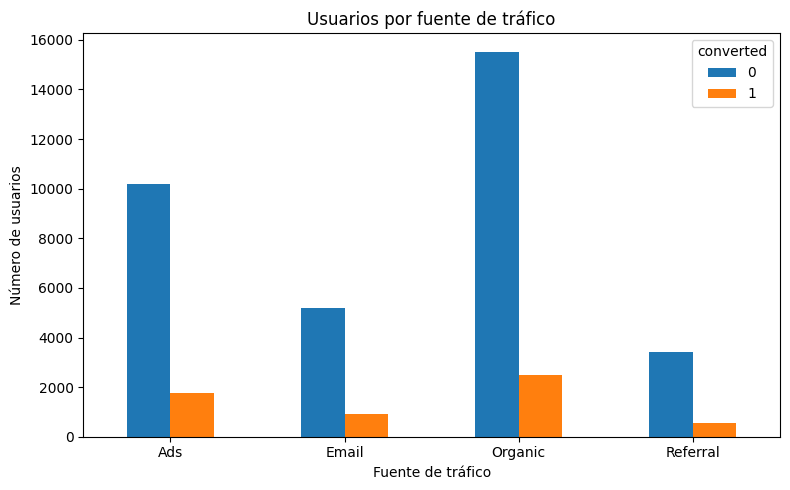

In [65]:

ax = tabla_traffic_source.plot(kind='bar', rot=0, figsize=(8, 5))
ax.set_title('Usuarios por fuente de tráfico')
ax.set_xlabel('Fuente de tráfico')
ax.set_ylabel('Número de usuarios')

plt.tight_layout()
plt.show()


In [57]:
proporciones_traffic= tabla_traffic_source.div(totales,axis=0)
print('Proporcion de usuarios que convirtieron y que no conviertieron')
print(proporciones_traffic)


Proporcion de usuarios que convirtieron y que no conviertieron
converted              0         1
traffic_source                    
Ads             0.852618  0.147382
Email           0.850073  0.149927
Organic         0.862123  0.137877
Referral        0.861188  0.138812


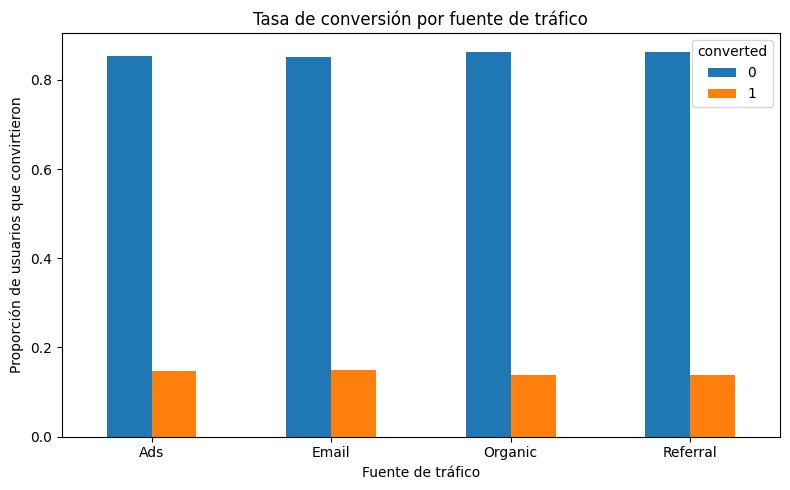

In [68]:
ax = proporciones_traffic.plot(kind='bar', rot=0, figsize=(8, 5))
ax.set_title('Tasa de conversión por fuente de tráfico')
ax.set_xlabel('Fuente de tráfico')
ax.set_ylabel('Proporción de usuarios que convirtieron')

plt.tight_layout()
plt.show()

✍️ **Comentario**: 
#### Totales: usuarios por fuente de tráfico

La gráfica muestra cuántos usuarios llegaron por cada canal. **Organic** es la principal fuente de tráfico, con 17,987 usuarios (≈ 45% del total), seguido de **Ads** (11,935), **Email** (6,123) y **Referral** (3,955). Esto indica el **volumen** de cada canal, no qué tan bien convierte. En términos absolutos, Organic también aporta más usuarios convertidos (≈ 2,480), simplemente porque trae más tráfico.

#### Proporciones: tasa de conversión por fuente de tráfico

La gráfica muestra, dentro de cada canal, qué porcentaje de usuarios convirtió. **Email** tiene la mayor tasa (14.99%), seguido de **Ads** (14.74%), **Referral** (13.88%) y **Organic** (13.79%). Como se compara la proporción dentro de cada grupo, esta vista permite contrastar canales sin que influya su tamaño. Las diferencias son **pequeñas** (≈ 1.2 puntos porcentuales entre el mejor y el peor canal), por lo que, aunque la prueba chi-cuadrado detecta una asociación, el efecto práctico es limitado.

**Lectura conjunta:** Organic es el canal con más volumen pero con la tasa más baja, mientras que Email es el de menor volumen y mayor tasa. Esto sugiere que mejorar la conversión del tráfico orgánico, aun en pequeña medida, tendría más impacto total que crecer los canales pequeños.

### Relación entre el tipo de usuario y la conversión

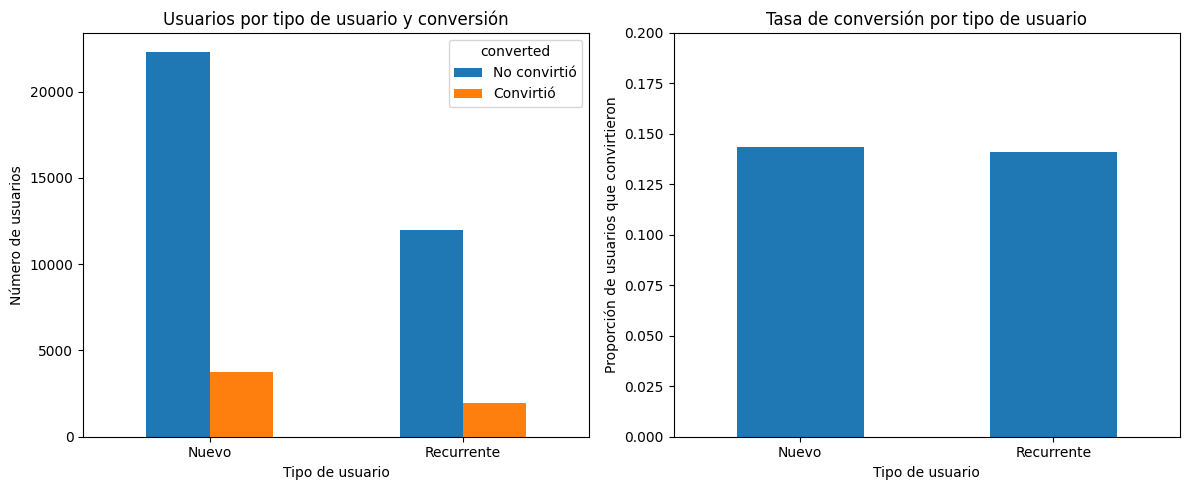

In [70]:

totales = pd.crosstab(df['user_type'], df['converted'])
proporciones = pd.crosstab(df['user_type'], df['converted'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

totales.plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Usuarios por tipo de usuario y conversión')
axes[0].set_xlabel('Tipo de usuario')
axes[0].set_ylabel('Número de usuarios')
axes[0].legend(title='converted', labels=['No convirtió', 'Convirtió'])

proporciones[1].plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Tasa de conversión por tipo de usuario')
axes[1].set_xlabel('Tipo de usuario')
axes[1].set_ylabel('Proporción de usuarios que convirtieron')
axes[1].set_ylim(0, 0.20)   # eje desde 0 para no exagerar la diferencia

plt.tight_layout()
plt.show()


✍️ **Comentario**: 
#### Totales: usuarios por tipo de usuario y conversión

La gráfica muestra cuántos usuarios de cada tipo convirtieron y cuántos no. Los **usuarios nuevos** son mayoría (26,033, ≈ 65% del total) frente a los **recurrentes** (13,967, ≈ 35%), y por eso aportan más conversiones en términos absolutos (3,738 contra 1,968). Esta vista refleja el **volumen** de cada grupo, no qué tan bien convierte.

#### Proporciones: tasa de conversión por tipo de usuario

La gráfica muestra, dentro de cada grupo, qué porcentaje de usuarios convirtió. Los **nuevos** convierten al **14.36%** y los **recurrentes** al **14.09%**, una diferencia de apenas ≈ 0.27 puntos porcentuales. Al comparar proporciones dentro de cada grupo, el tamaño de cada segmento no influye, y las barras prácticamente se igualan.



✍️ **Comentario**: Haz doble clic en este bloque y complementa el gráfico con un breve texto que explique qué estamos viendo.

Comienza a escribir debajo de este texto, una vez escritas tus conclusiones, **elimina estas instrucciones** (de aqui hacia arriba de este bloque) para dejar solamente tus hallazgos.

## 🧩  Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**

**Gasto promedio por usuario que convirtió:**
- La diferencia es estadísticamente significativa (t = −9.37, p < 0.001); el tamaño del efecto es pequeño a moderado (d de Cohen ≈ 0.25), pero muy consistente.
- **Interpretación:** la página B no solo atrae más clientes, sino que cada cliente vale más. Eso sugiere que el rediseño comunica mejor la propuesta de valor y no solo capta usuarios con menor intención de compra.

**Tasa de conversión:**
- La página **B** convierte al **15.96%** (3,194 de 20,018 usuarios) frente al **12.57%** de la A (2,512 de 19,982).
- La diferencia es de **+3.38 puntos porcentuales** (≈ 27% más conversión relativa) y es estadísticamente significativa (χ² = 93.65, p < 0.001).
- **Interpretación:** por cada 100 visitantes, B consigue ≈ 3.4 clientes más que A, es decir, ≈ 680 conversiones adicionales en los 28 días del experimento. Con más conversiones y mayor gasto por cliente, **B genera más valor económico por ambas vías**.

#### 📊 **Segmentación por fuente de tráfico**
- Existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión, pero **de magnitud pequeña**: Email convierte al 14.99%, Ads al 14.74%, Referral al 13.88% y Orgánico al 13.79% (≈ 1.2 puntos porcentuales entre el mejor y el peor canal).
- Orgánico aporta ≈ 45% del tráfico (17,987 de 40,000 usuarios) y, aun con la tasa más baja, genera el mayor número de conversiones en términos absolutos.
- **Interpretación:** todos los canales convierten de forma parecida, con Email y Ads ligeramente por encima. Como Orgánico concentra el volumen, mejorar un poco su conversión tendría más impacto total que crecer los canales pequeños. Las diferencias entre canales no justifican por sí solas reasignar presupuesto sin considerar costos.

#### 📊 **Segmentación por tipo de usuario**
- No hay diferencias significativas: los usuarios nuevos convierten al **14.36%** y los recurrentes al **14.09%** (χ² = 0.513, p = 0.474; diferencia de 0.27 puntos porcentuales, dentro del azar).
- **Interpretación:** ser nuevo o recurrente no cambia de forma apreciable la probabilidad de convertir, por lo que la misma landing funciona para ambos y no se requiere una estrategia de conversión distinta por tipo de usuario.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:**
- **Adoptar la versión B como landing principal:** convierte más y sus clientes gastan más. Monitorear la conversión después del lanzamiento para confirmar que se sostiene y no es un efecto de novedad.
- **Medir el impacto en ingresos:** calcular el ingreso por usuario expuesto (conversión × gasto) en A y en B para cuantificar el beneficio total del cambio.
- **Optimizar la experiencia del tráfico orgánico:** al ser el canal más grande, ajustar contenido y llamadas a la acción (por ejemplo, capturar el correo para llevarlo al canal de email) tiene el mayor impacto potencial.
- **Evaluar canales por retorno, no solo por conversión:** Email y Ads rinden algo más, pero la decisión de presupuesto debe incluir costo de adquisición y gasto promedio por canal.
- **No segmentar por tipo de usuario:** concentrar el esfuerzo en la versión de landing y en los canales.
- **Siguiente paso:** identificar qué elemento específico de B explica la mejora, y confirmar que B gana también por dispositivo y región.